Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import learning_curve
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

Load and Inspect the Dataset

In [3]:
file_path = "LoanData_Preprocessed_v1.2.csv"
df = pd.read_csv(file_path)

print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 485 entries, 0 to 484
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       485 non-null    int64  
 1   employ    485 non-null    int64  
 2   address   485 non-null    int64  
 3   income    485 non-null    float64
 4   debtinc   485 non-null    float64
 5   creddebt  485 non-null    float64
 6   othdebt   485 non-null    float64
 7   ed        485 non-null    int64  
 8   default   485 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 34.2 KB
None
   age  employ  address  income  debtinc  creddebt    othdebt  ed  default
0   29      11        7    32.0      6.0  0.927360   0.992640   1        0
1   28       1        3    26.0     12.4  0.377208   2.846792   4        0
2   34      16        3    75.0     10.4  3.954600   3.845400   1        0
3   51      31       14   249.0      7.8  4.272840  15.149160   2        0
4   40      13       11   102.0     

Summary Statistics and Class Balance

In [4]:
summary_stats = df.describe()
print(summary_stats)

class_balance = df['default'].value_counts(normalize=True) * 100
print("\nClass Balance (%):\n", class_balance)


              age      employ     address      income     debtinc    creddebt  \
count  485.000000  485.000000  485.000000  485.000000  485.000000  485.000000   
mean    35.053608    8.239175    8.501031   44.448802   10.217320    1.407004   
std      8.003177    6.557479    7.013159   31.604135    6.747319    1.517178   
min     21.000000    0.000000    0.000000   14.000000    0.600000    0.014835   
25%     29.000000    3.000000    3.000000   24.000000    5.000000    0.376852   
50%     34.000000    7.000000    7.000000   36.000000    8.600000    0.856075   
75%     41.000000   12.000000   13.000000   51.000000   14.000000    1.874560   
max     56.000000   31.000000   34.000000  249.000000   36.600000    9.600480   

          othdebt          ed     default  
count  485.000000  485.000000  485.000000  
mean     2.938476    1.740206    0.249485  
std      2.964370    0.948320    0.433161  
min      0.045584    1.000000    0.000000  
25%      1.054992    1.000000    0.000000  
50%   

Correlation Analysis and Visualization

<temp>\3984826738.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='default', data=df, ax=axes[0, 0], palette='Set2')


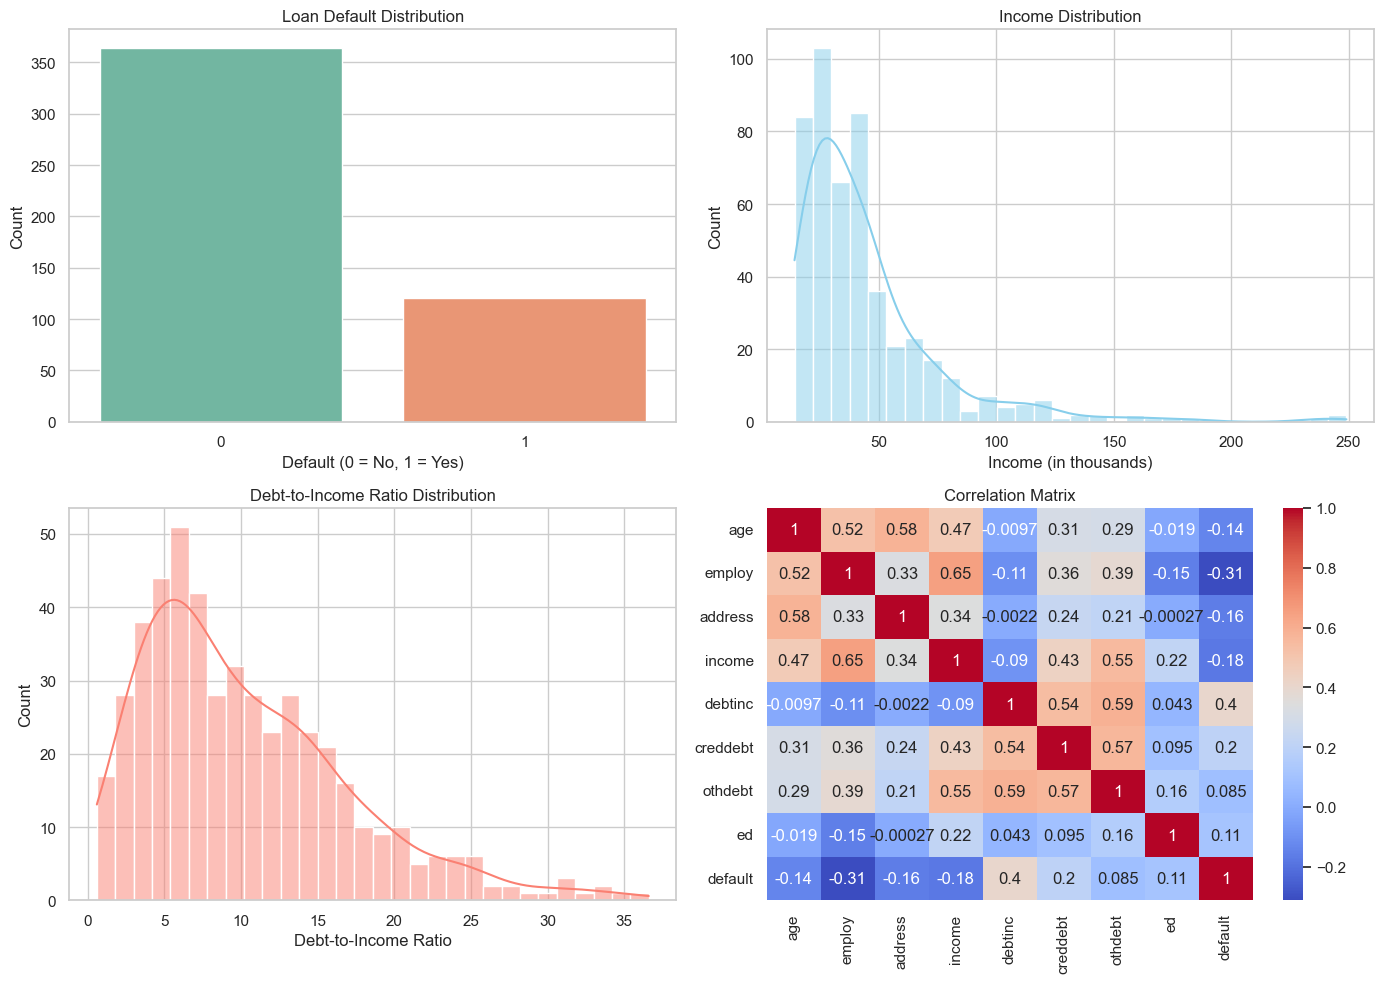

In [5]:
correlation_matrix = df.corr()

sns.set(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x='default', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Loan Default Distribution')
axes[0, 0].set_xlabel('Default (0 = No, 1 = Yes)')
axes[0, 0].set_ylabel('Count')

sns.histplot(df['income'], kde=True, bins=30, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Income Distribution')
axes[0, 1].set_xlabel('Income (in thousands)')

sns.histplot(df['debtinc'], kde=True, bins=30, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Debt-to-Income Ratio Distribution')
axes[1, 0].set_xlabel('Debt-to-Income Ratio')

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()


 Data Splitting

In [ ]:
X = df.drop('default', axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

Training Set Shape: (388, 8)
Testing Set Shape: (97, 8)


Data Standardization

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Set Shape (Scaled):", X_train_scaled.shape)
print("Testing Set Shape (Scaled):", X_test_scaled.shape)

Training Set Shape (Scaled): (388, 8)
Testing Set Shape (Scaled): (97, 8)


Logistic Regression

In [ ]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_logreg = log_reg.predict(X_test_scaled)
y_prob_logreg = log_reg.predict_proba(X_test_scaled)[:, 1]

print("\nLogistic Regression Report:\n", classification_report(y_test, y_pred_logreg))
print("ROC-AUC Score (Logistic Regression):", roc_auc_score(y_test, y_prob_logreg))


Logistic Regression Report:
               precision    recall  f1-score   support

           0       0.82      0.95      0.88        73
           1       0.69      0.38      0.49        24

    accuracy                           0.80        97
   macro avg       0.76      0.66      0.68        97
weighted avg       0.79      0.80      0.78        97

ROC-AUC Score (Logistic Regression): 0.872716894977169


Support Vector Machine (SVM)

In [9]:
svm_clf = SVC(probability=True, random_state=42)
svm_clf.fit(X_train_scaled, y_train)

y_pred_svm = svm_clf.predict(X_test_scaled)
y_prob_svm = svm_clf.predict_proba(X_test_scaled)[:, 1]

print("\nSVM Report:\n", classification_report(y_test, y_pred_svm))
print("ROC-AUC Score (SVM):", roc_auc_score(y_test, y_prob_svm))



SVM Report:
               precision    recall  f1-score   support

           0       0.79      0.96      0.86        73
           1       0.62      0.21      0.31        24

    accuracy                           0.77        97
   macro avg       0.71      0.58      0.59        97
weighted avg       0.75      0.77      0.73        97

ROC-AUC Score (SVM): 0.8105022831050228


ROC Curve Comparison

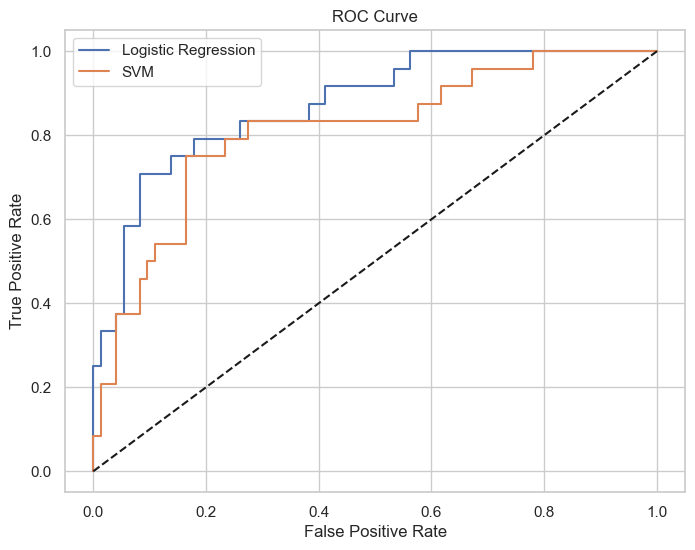

In [10]:
plt.figure(figsize=(8, 6))
fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_prob_logreg)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

plt.plot(fpr_logreg, tpr_logreg, label='Logistic Regression')
plt.plot(fpr_svm, tpr_svm, label='SVM')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


Overfitting/Underfitting Diagnostics

Logistic AUC → Train: 0.845  Test: 0.873
SVM AUC → Train: 0.874  Test: 0.811


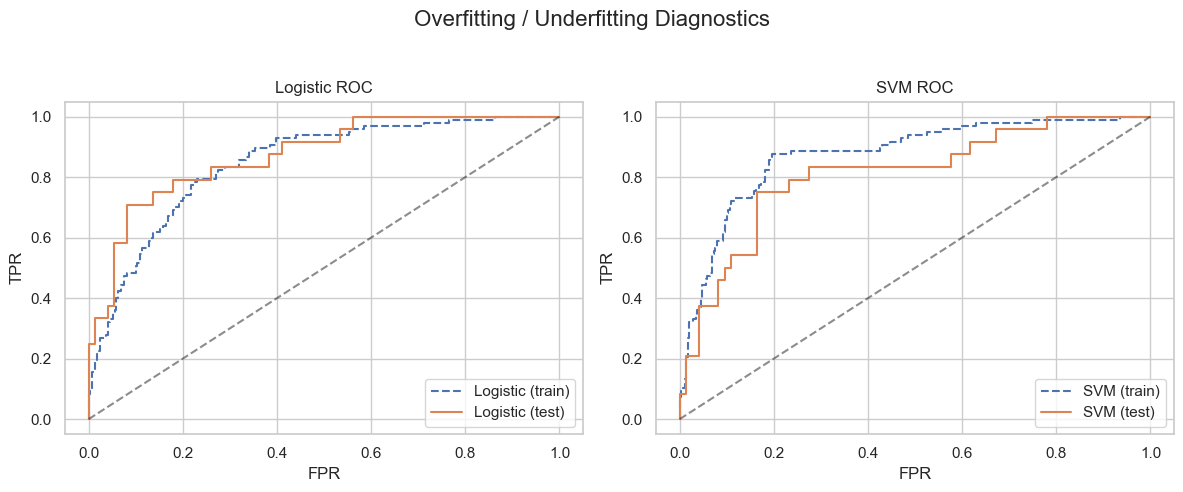

In [ ]:
def plot_train_test_roc_ax(ax, model, X_tr, y_tr, X_te, y_te, name):
    p_tr = model.predict_proba(X_tr)[:,1]
    p_te = model.predict_proba(X_te)[:,1]

    fpr_tr, tpr_tr, _ = roc_curve(y_tr, p_tr)
    fpr_te, tpr_te, _ = roc_curve(y_te, p_te)

    auc_tr = roc_auc_score(y_tr, p_tr)
    auc_te = roc_auc_score(y_te, p_te)
    print(f"{name} AUC → Train: {auc_tr:.3f}  Test: {auc_te:.3f}")

    ax.plot(fpr_tr, tpr_tr, linestyle='--', label=f'{name} (train)')
    ax.plot(fpr_te, tpr_te, linestyle='-',  label=f'{name} (test)')
    ax.plot([0,1], [0,1], 'k--', alpha=0.5)
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.set_title(f'{name} ROC')
    ax.legend(loc='lower right')
    ax.grid(True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

plot_train_test_roc_ax(
    ax1,
    log_reg,
    X_train_scaled, y_train,
    X_test_scaled,  y_test,
    'Logistic'
)

plot_train_test_roc_ax(
    ax2,
    svm_clf,
    X_train_scaled, y_train,
    X_test_scaled,  y_test,
    'SVM'
)

fig.suptitle('Overfitting / Underfitting Diagnostics', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()